# Confusion Matrix

In [43]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [40]:
data = json.load(open("model_metrics.json"))

In [41]:
metrics = ['accuracy', 'precision', 'recall', 'f1_score']

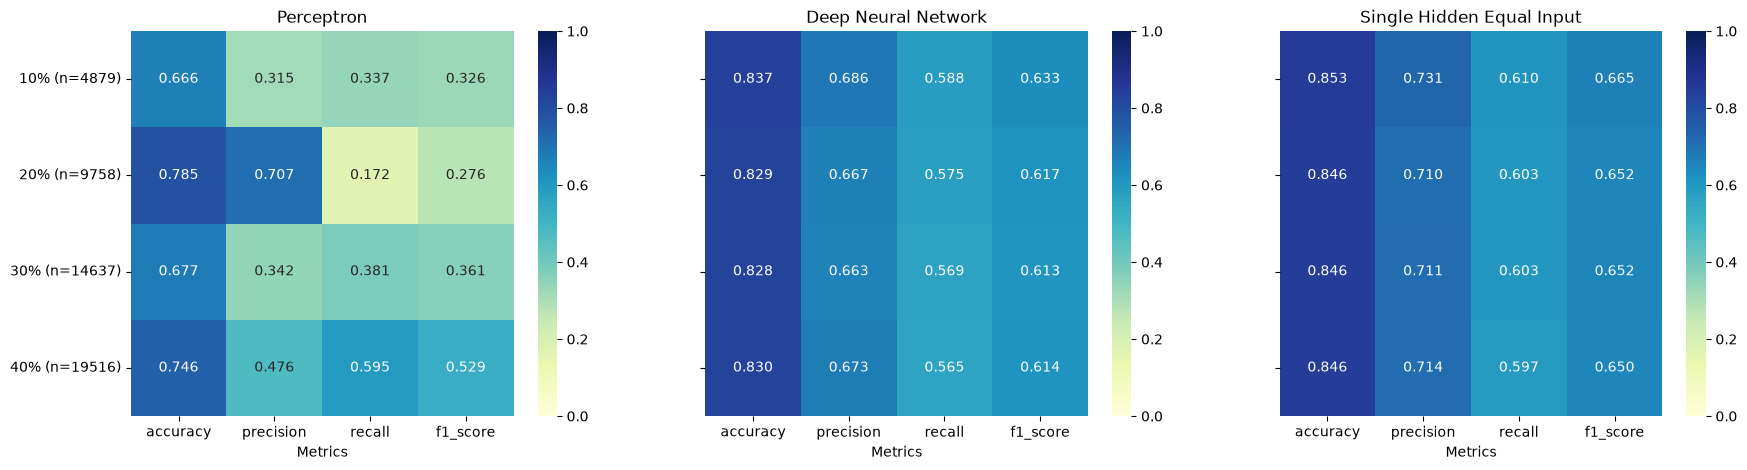

In [49]:
fig, axes = plt.subplots(1, len(data), figsize=(7 * len(data), 5), sharey=True)

for ax, (model_name, splits) in zip(axes, data.items()):
    df = pd.DataFrame(splits).T
    df = df.loc[sorted(df.index, key=lambda x: int(x.strip("%")))]
    y_labels = [f"{pct} (n={int(row['samples'])})" for pct, row in df.iterrows()]
    
    sns.heatmap(
        df[metrics],
        annot=True,          
        fmt=".3f",           
        cmap="YlGnBu",       
        vmin=0, vmax=1,      
        yticklabels=y_labels,
        ax=ax
    )
    ax.set_title(model_name.replace("_", " ").title())
    ax.set_xlabel("Metrics")
plt.show()

In [53]:
for model_name, splits in data.items():
    fig, ax = plt.subplots(figsize=(7, 5))
    
    df = pd.DataFrame(splits).T
    df = df.loc[sorted(df.index, key=lambda x: int(x.strip("%")))]
    y_labels = [f"{pct} (n={int(row['samples'])})" for pct, row in df.iterrows()]
    
    sns.heatmap(
        df[metrics],
        annot=True,
        fmt=".3f",
        cmap="YlGnBu",
        vmin=0, vmax=1,
        yticklabels=y_labels,
        ax=ax
    )
    ax.set_title(model_name.replace("_", " ").title())
    ax.set_xlabel("Metrics")
    ax.set_ylabel("Data Split")
    
    plt.tight_layout()
    plt.savefig(f"{model_name}_performance_heatmap.png", dpi=300, bbox_inches="tight")
    plt.close(fig)